In [1]:
from google.colab import files
uploaded = files.upload()

Saving diabetes_screening_data - diabetes_screening_data.csv to diabetes_screening_data - diabetes_screening_data.csv


In [3]:
import pandas as pd

df = pd.read_csv("diabetes_screening_data - diabetes_screening_data.csv")
print(df.shape)
print(df.head())

(768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Class Distribution:")
print(df['Outcome'].value_counts())

Dataset Shape: (768, 9)

Column Names:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

Data Types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    i

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Duplicate Rows: 0

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Target Class Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [5]:
import numpy as np

cols = ['Glucose', 'BloodPressure', 'SkinThickness',
        'Insulin', 'BMI']

for col in cols:
    print(col, ":", (df[col] == 0).sum())

Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


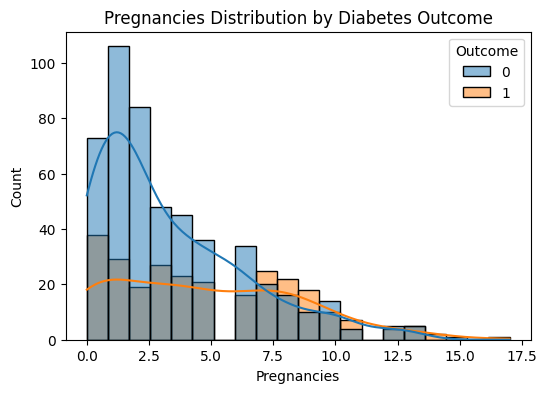

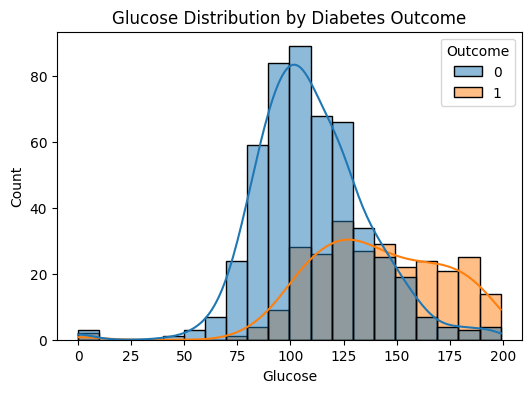

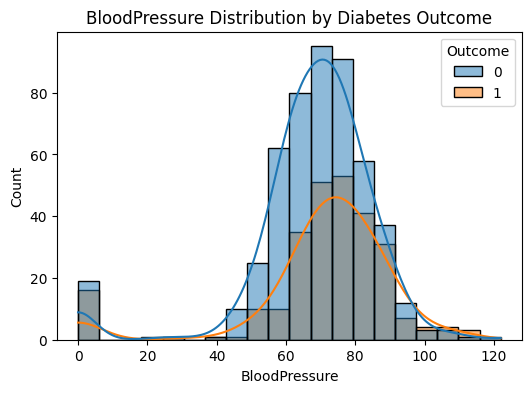

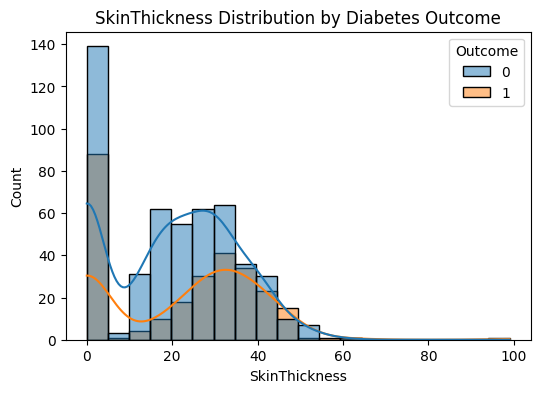

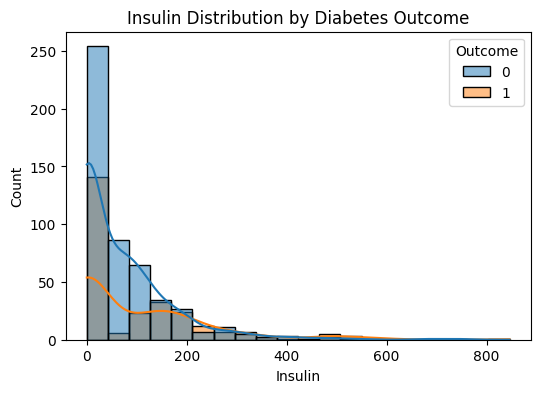

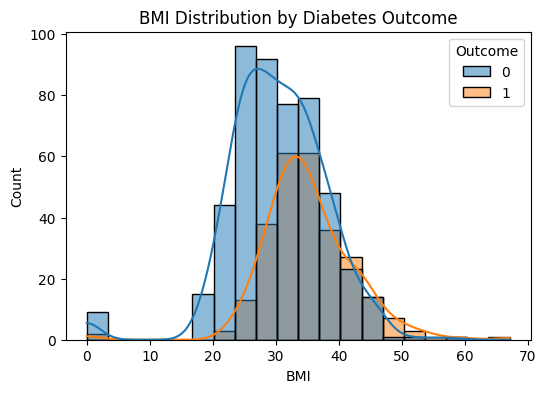

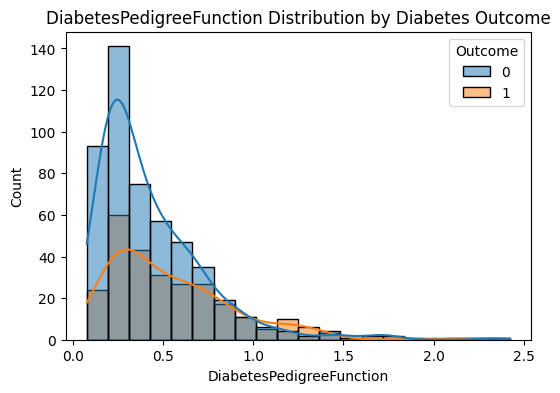

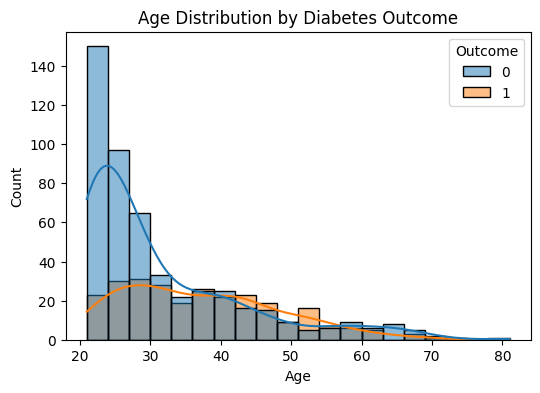

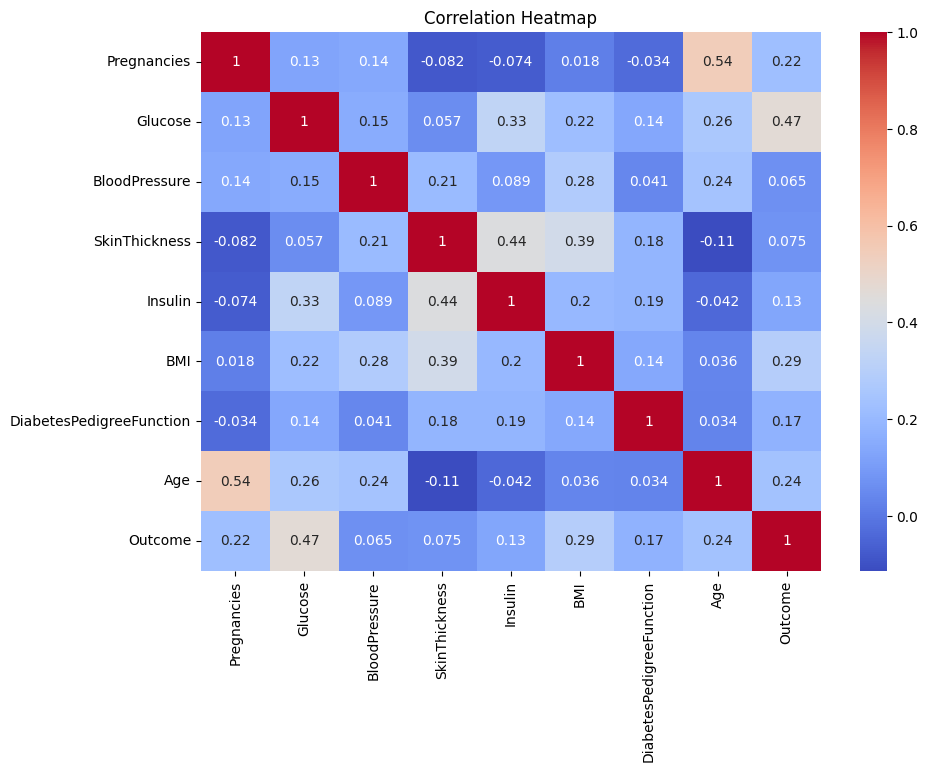

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in df.columns[:-1]:
    plt.figure(figsize=(6,4))
    sns.histplot(data=df, x=col, hue='Outcome',
                 kde=True, bins=20)
    plt.title(f'{col} Distribution by Diabetes Outcome')
    plt.show()

plt.figure(figsize=(10,7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [7]:
# Create new features

df['ObesityFlag'] = (df['BMI'] >= 30).astype(int)

df['Age35Plus'] = (df['Age'] >= 35).astype(int)

df['MissingMeasurementCount'] = (
    (df['Glucose'] == 0).astype(int) +
    (df['BloodPressure'] == 0).astype(int) +
    (df['SkinThickness'] == 0).astype(int) +
    (df['Insulin'] == 0).astype(int) +
    (df['BMI'] == 0).astype(int)
)

df['GlucoseBMIInteraction'] = df['Glucose'] * df['BMI']

print("New features created successfully!")
display(df.head())

New features created successfully!


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ObesityFlag,Age35Plus,MissingMeasurementCount,GlucoseBMIInteraction
0,6,148,72,35,0,33.6,0.627,50,1,1,1,1,4972.8
1,1,85,66,29,0,26.6,0.351,31,0,0,0,1,2261.0
2,8,183,64,0,0,23.3,0.672,32,1,0,0,2,4263.9
3,1,89,66,23,94,28.1,0.167,21,0,0,0,0,2500.9
4,0,137,40,35,168,43.1,2.288,33,1,1,0,0,5904.7


In [8]:
from sklearn.model_selection import train_test_split

# Replace invalid zero values with NaN
cols = ['Glucose', 'BloodPressure', 'SkinThickness',
        'Insulin', 'BMI']

df[cols] = df[cols].replace(0, np.nan)

X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 12)
Testing data: (154, 12)


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "XGBoost": XGBClassifier(
        eval_metric='logloss',
        random_state=42,
        n_jobs=1
    )
}

scaled_models = ["Logistic Regression", "KNN", "SVM"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in models.items():
    steps = [('imputer', SimpleImputer(strategy='median'))]

    if name in scaled_models:
        steps.append(('scaler', StandardScaler()))

    steps.append(('model', model))
    pipe = Pipeline(steps)

    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
        return_train_score=True,
        n_jobs=1
    )

    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean(),
        'ROC_AUC': scores['test_roc_auc'].mean(),
        'Train Accuracy': scores['train_accuracy'].mean()
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Train Accuracy
0,Logistic Regression,0.780,0.740,0.580,0.647,0.840,0.790
1,KNN,0.759,0.679,0.594,0.632,0.789,0.823
2,Decision Tree,0.700,0.570,0.589,0.577,0.674,1.000
3,Random Forest,0.778,0.721,0.608,0.657,0.816,1.000
4,SVM,0.772,0.749,0.533,0.617,0.822,0.834
5,XGBoost,0.726,0.618,0.575,0.594,0.778,1.000


In [10]:
from sklearn.model_selection import RandomizedSearchCV

# 1. Logistic Regression
lr_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=2000))
])

lr_params = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced']
}

# 2. Random Forest
rf_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(random_state=42))
])

rf_params = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__class_weight': [None, 'balanced']
}

# 3. SVM
svm_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', SVC(probability=True, random_state=42))
])

svm_params = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': ['scale', 'auto', 0.01, 0.1],
    'model__class_weight': [None, 'balanced']
}

searches = {
    'Logistic Regression': (lr_pipe, lr_params),
    'Random Forest': (rf_pipe, rf_params),
    'SVM': (svm_pipe, svm_params)
}

best_models = {}
tuning_results = []

for name, (pipe, params) in searches.items():

    search = RandomizedSearchCV(
        pipe,
        params,
        n_iter=10,
        scoring='roc_auc',
        cv=cv,
        random_state=42,
        n_jobs=1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        'Model': name,
        'Best CV ROC-AUC': search.best_score_,
        'Best Parameters': search.best_params_
    })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.842947,"{'model__class_weight': 'balanced', 'model__C'..."
1,Random Forest,0.837512,"{'model__n_estimators': 200, 'model__min_sampl..."
2,SVM,0.833585,"{'model__gamma': 'scale', 'model__class_weight..."


FINAL MODEL: Logistic Regression
Accuracy: 0.7467532467532467
Precision: 0.6119402985074627
Recall: 0.7592592592592593
F1 Score: 0.6776859504132231
ROC-AUC: 0.8214814814814814

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.74      0.79       100
           1       0.61      0.76      0.68        54

    accuracy                           0.75       154
   macro avg       0.73      0.75      0.73       154
weighted avg       0.77      0.75      0.75       154



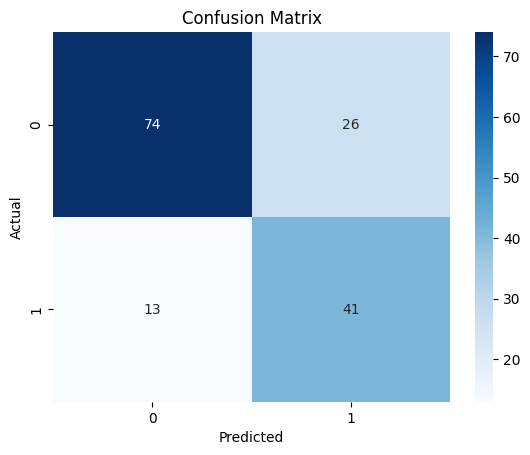

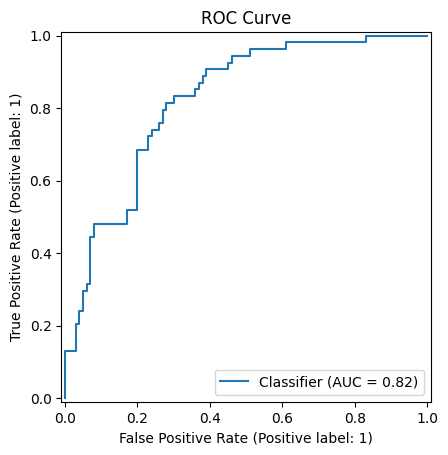

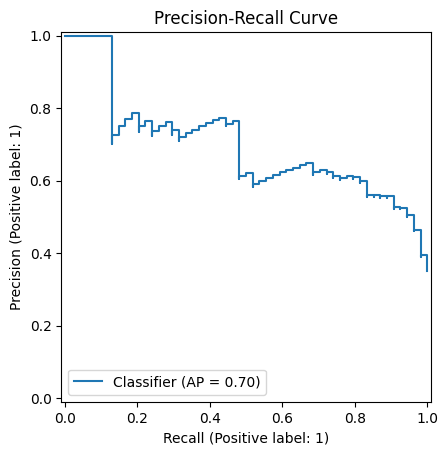

False Negatives: 13
False Positives: 26


In [11]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, RocCurveDisplay,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt
import seaborn as sns

# Select best model using CV results
final_model = best_models['Logistic Regression']

# Predict on test data (first and only final evaluation)
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("FINAL MODEL: Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve")
plt.show()

# Precision Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Precision-Recall Curve")
plt.show()

print("False Negatives:", cm[1][0])
print("False Positives:", cm[0][1])

In [12]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Generate out-of-fold probabilities using training data only
oof_prob = cross_val_predict(
    final_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

# Find threshold with recall >= 85% and highest precision
best_threshold = None
best_precision = -1

for threshold in np.arange(0.05, 0.96, 0.01):
    oof_pred = (oof_prob >= threshold).astype(int)

    recall = recall_score(y_train, oof_pred)
    precision = precision_score(
        y_train, oof_pred, zero_division=0
    )

    if recall >= 0.85 and precision > best_precision:
        best_precision = precision
        best_threshold = threshold

print("Selected Threshold:", best_threshold)
print("Training OOF Precision:", best_precision)

# Apply selected threshold to test probabilities
if best_threshold is not None:
    tuned_pred = (y_prob >= best_threshold).astype(int)

    print("\nDEFAULT THRESHOLD (0.50)")
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1:", f1_score(y_test, y_pred))

    print("\nTUNED THRESHOLD")
    print("Precision:", precision_score(y_test, tuned_pred))
    print("Recall:", recall_score(y_test, tuned_pred))
    print("F1:", f1_score(y_test, tuned_pred))

    print("\nTuned Confusion Matrix:")
    print(confusion_matrix(y_test, tuned_pred))

else:
    print("No threshold achieved the target recall.")

Selected Threshold: 0.36000000000000004
Training OOF Precision: 0.538235294117647

DEFAULT THRESHOLD (0.50)
Precision: 0.6119402985074627
Recall: 0.7592592592592593
F1: 0.6776859504132231

TUNED THRESHOLD
Precision: 0.5542168674698795
Recall: 0.8518518518518519
F1: 0.6715328467153284

Tuned Confusion Matrix:
[[63 37]
 [ 8 46]]


In [15]:
import joblib

joblib.dump(final_model, 'sugarsense_model.joblib')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
# SugarSense – Early Diabetes Risk Screening

## Conclusion

The SugarSense project developed a machine learning model to identify potential diabetes risk using patient health measurements.

Six machine learning algorithms were compared: Logistic Regression, KNN, Decision Tree, Random Forest, SVM, and XGBoost.

After cross-validation and hyperparameter tuning, Logistic Regression was selected as the final model with a cross-validation ROC-AUC of 0.843.

On the test dataset, the model achieved:
- Accuracy: 74.68%
- Precision: 61.19%
- Recall: 75.93%
- F1-score: 67.77%
- ROC-AUC: 82.15%

Threshold tuning using training out-of-fold predictions selected a threshold of 0.36. At this threshold, test recall increased to 85.19%, while precision decreased to 55.42%.

This demonstrates a trade-off between identifying more potential diabetes cases and increasing false-positive predictions.

## Limitations

1. The dataset contains only 768 records.
2. The dataset includes only female patients aged 21 years and above.
3. Some measurements contain zero values that were treated as missing.
4. The model may not generalize to all populations.
5. The model is intended for educational risk screening, not medical diagnosis.

## Ethical Considerations

Patient privacy, fairness, and responsible use of predictions are important. The model should not replace professional medical advice or diagnosis.

## Future Scope

- Use larger and more diverse datasets.
- Test additional machine learning algorithms.
- Improve model performance and fairness.
- Develop a simple web application for risk screening.